# Heat loss of a house explained simply

**Lab 4: Thermal losses for a house.** First we count how much heat a house loses in winter, then we lower the indoor temperature as far as people still feel fine.

## Words and symbols

> **tE / tI**: exterior / interior air temperature. Outside = 5 degC, inside = 24 degC

> **W, kW, kWh**: watt, kilowatt, kilowatt-hour. Power is **how fast** energy flows; **kWh = power x hours**, what the electricity bill counts

> **lambda**: thermal conductivity [W/(m K)]. How easily a material **lets heat through** (small = good insulator)

> **R**: thermal resistance [m2 K/W]. How **hard** it is for heat to pass; thickness divided by lambda; bigger = better

> **k** (or U): overall heat transfer coefficient [W/(m2 K)]. How many watts leak through **one square metre for each degree** of temperature difference; small = good wall

> **alpha**: convection coefficient [W/(m2 K)]. How well the **air next to the surface** takes or gives heat

> **q**: heat flux [W/m2]. Watts leaking through one square metre

> **EPS / XPS**: expanded / extruded polystyrene. White foam boards used as insulation

> **AAC**: autoclaved aerated concrete. Very light concrete full of tiny air bubbles (warm blocks)

> **PMV / PPD**: Predicted Mean Vote / Percentage Dissatisfied. The comfort vote (0 = just right, -0.5 to +0.5 is "good enough") and how many would complain

> **clo / met**: clothing / activity. How warm the clothes are and how fast the body's engine runs

> **setpoint**: the target. The temperature we tell the heater to hold

# Part 0: How does heat travel?

Heat always moves from **warm to cold**, never the other way round. A house in winter is warm inside and cold outside, so heat keeps trying to **escape**.

> **Conduction**: heat passes **through** a solid (a spoon in hot soup warms up).

> **Convection**: moving air or water **carries** heat (the breath of air that cools your soup).

> **Radiation**: warm surfaces **shine** heat at you (warmth of a campfire, or the chill near a cold window).

**The wall is a sandwich.** Heat leaves the room air (convection), crosses each layer of the wall (conduction) and finally goes into the outside air (convection again).

![Three ways heat moves: conduction, convection and radiation](images/heat-transfer-modes.svg)

*Figure: Three ways heat moves: conduction, convection and radiation*

> **Insulation** is a blanket for the house. Materials with a small *lambda* (foam, mineral wool, air bubbles) let almost no heat pass. A thick layer of them makes heat **very slow**.

> **Thermal resistance** = how hard heat finds it to pass. Each layer has $R = \text{thickness} / \lambda$.

Stack the layers and **the resistances add up**, like hurdles in a race. The heat flux is then simply

$$q = k \cdot (t_I - t_E), \qquad k = 1/R_{total}$$

so a **small k** means a warm, cheap house.

> **Steady state**: nothing changes with time. All our numbers assume that the temperatures stay constant and the walls store no heat, which keeps the maths simple.

**Windows let the sun in.** A window loses heat to the cold outside, but on a sunny day the sun also pushes heat **in**. At noon on the south side the sun can win, and the window becomes a tiny heater.

![The house: walls, windows, floor on the soil and the ceiling towards the heated floor above](images/house-envelope.svg)

*Figure: The house: walls, windows, floor on the soil and the ceiling towards the heated floor above*

In [1]:
import sys; sys.path.insert(0, "../../shared")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from heat_loss import (WALL, FLOOR, CEILING, ALPHA_I_WALL, ALPHA_E, T_I, T_E, layer_table, total_resistance, k_value,
                       temperature_profile, wall_flux, total_load, without_layer, electricity_kwh,
                       insulation_sweep, wall_options, pmv, optimal_setpoint, savings)
from calculate_pmv_ppd import calculate_pmv_ppd
ppd = lambda *a: calculate_pmv_ppd(*a)[1]

BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#d03b3b"
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.edgecolor": MUTED, "axes.labelcolor": INK, "xtick.color": MUTED, "ytick.color": MUTED,
                     "text.color": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "figure.dpi": 110, "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold"})

Data from the sheet: outside **5 degC**, inside **24 degC**, soil **11 degC**; the house is 6 m x 6 m with 3 m high walls and only the ground floor is studied.

# Q1: How much heat leaks through one square metre of wall?

**Idea.** The wall has five layers. We add up the "hardness" (R) of every layer plus the air films on both sides, then multiply by the temperature difference.

**Wall, from outside to inside:** decorative plaster 0.5 cm, polystyrene EPS 10 cm, cement mortar 0.3 cm, AAC blocks 25 cm, cement mortar 0.2 cm.

> **Plaster**: a thin coat on the surface.

> **Mortar**: the cement-and-sand layer that glues and smooths the blocks.

![The five layers of the wall, from outside to inside](images/wall-layers.svg)

*Figure: The five layers of the wall, from outside to inside*

![Resistances in a row: heat meets each one and the temperature drops across the big ones](images/resistance-network.svg)

*Figure: Resistances in a row: heat meets each one and the temperature drops across the big ones*

In [2]:
layers = layer_table(WALL)
r_in, r_out = 1 / ALPHA_I_WALL, 1 / ALPHA_E
r_total = total_resistance(WALL, ALPHA_I_WALL, ALPHA_E)
k = k_value(WALL, ALPHA_I_WALL, ALPHA_E)
q = wall_flux()
print(f"R inside air film = {r_in:.3f}, R layers = {layers.R_m2K_W.sum():.3f}, R outside air film = {r_out:.3f}  (m2K/W)")
print(f"R total = {r_total:.3f} m2K/W  ->  k = {k:.4f} W/m2K")
print(f"Heat flux through the wall: q = {q:.2f} W per m2 (inside {T_I} degC, outside {T_E} degC)")

R inside air film = 0.125, R layers = 4.381, R outside air film = 0.042  (m2K/W)
R total = 4.547 m2K/W  ->  k = 0.2199 W/m2K
Heat flux through the wall: q = 4.18 W per m2 (inside 24.0 degC, outside 5.0 degC)


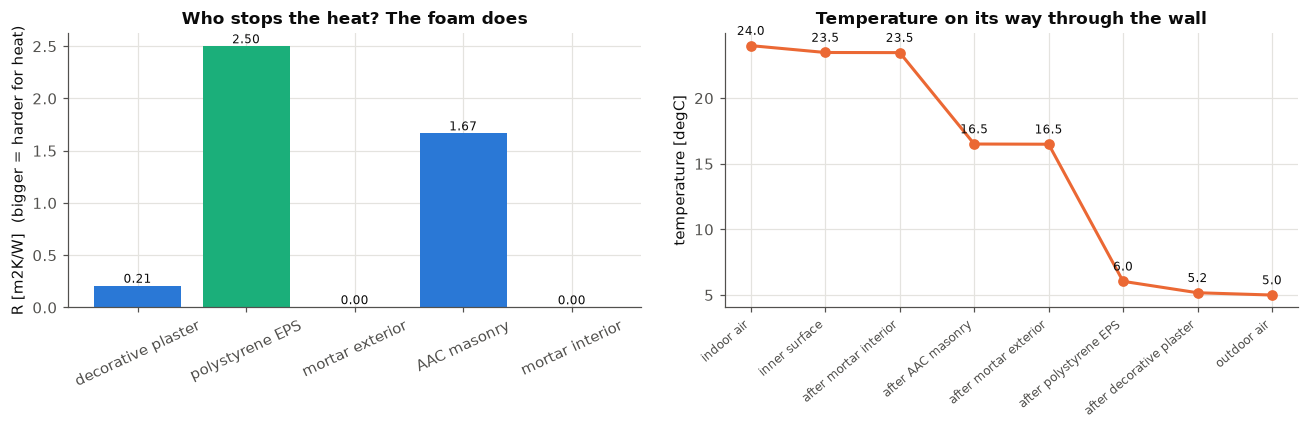

In [3]:
prof = temperature_profile(WALL, ALPHA_I_WALL, ALPHA_E, T_I, T_E)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(layers.layer, layers.R_m2K_W, color=[AQUA if "polystyrene" in n else BLUE for n in layers.layer])
ax[0].bar_label(ax[0].containers[0], fmt="%.2f", fontsize=8)
ax[0].set_ylabel("R [m2K/W]  (bigger = harder for heat)"); ax[0].tick_params(axis="x", rotation=25)
ax[0].set_title("Who stops the heat? The foam does")
ax[1].plot(range(len(prof)), prof.temp, "o-", color=ORANGE, lw=2)
for i, t in enumerate(prof.temp): ax[1].annotate(f"{t:.1f}", (i, t), textcoords="offset points", xytext=(0, 7), ha="center", fontsize=8)
ax[1].set_xticks(range(len(prof))); ax[1].set_xticklabels(prof.point, rotation=40, ha="right", fontsize=8)
ax[1].set_ylabel("temperature [degC]"); ax[1].set_title("Temperature on its way through the wall")
plt.tight_layout(); plt.show()

**What this means.**
* The whole wall has a total hardness of **R = 4.55 m2K/W**, so **k = 0.22 W/(m2K)**: for every degree of difference, only 0.22 watts leak through each square metre.
* With 19 degrees of difference (24 inside, 5 outside) the flux is **q = 4.18 W per square metre**, about the power of a small night light spread over each square metre.
* **The foam is the hero:** the 10 cm of EPS has R = 2.50, more than half of the total, although it is thinner than the 25 cm of AAC (R = 1.67). The air films add only 0.17 together, the thin decorative plaster adds 0.21 (it conducts very little, lambda 0.024), and the two mortar layers are almost nothing.
* **Where does the temperature drop?** The inner wall surface is still **23.5 degC**, almost like the room. The temperature falls to **16.5 degC** after the AAC and to **6.0 degC** after the foam. So the cold stays outside the foam, and the inside of the wall feels warm. This also tells us walls are not the cold "radiators" that make people uncomfortable.

# Q2: How many kilowatt-hours does the radiator need each hour?

> **Electric radiator**: a heater with a hot element that turns every watt of electricity into one watt of heat.

**Idea.** To keep the house at 24 degC, it must replace **exactly the heat that leaks out**. So hourly energy = total heat loss in watts x 1 hour.

**The house has four parts that lose (or gain) heat:**
* **Walls** (72 m2 gross minus 4 m2 of windows = 68 m2),
* **Two windows** (east and south, 2 m2 each), where the sun gives some heat back,
* **Floor** on the ground, losing heat to the soil at 11 degC,
* **Ceiling**: the floor above is heated to 24 degC too, so **no heat goes through it**.

> **Solar irradiance** (I_T) [W/m2]: the sunshine power on one square metre of window.

> **Screed**: a cement-and-sand layer that levels the floor.

> **Infiltration**: cold air leaking in through cracks.

> **Thermal inertia**: heavy walls storing heat and releasing it later.

**Two simplifications from the sheet:** we ignore infiltration and thermal inertia.

**Two cases:** (a) the wall as designed, and (b) the wall **without the polystyrene**.

![A window: heat lost to the cold outside, minus the sunshine that gets in](images/window-heat-balance.svg)

*Figure: A window: heat lost to the cold outside, minus the sunshine that gets in*

![The floor: heat passes through the layers and the soil to a constant deep temperature](images/floor-to-soil.svg)

*Figure: The floor: heat passes through the layers and the soil to a constant deep temperature*

In [4]:
with_eps = total_load()
no_eps = total_load(wall_layers=without_layer(WALL, "polystyrene EPS"))
print(f"(a) with polystyrene   : {with_eps['total']:6.1f} W  ->  {electricity_kwh(with_eps['total']):.3f} kWh every hour")
print(f"(b) without polystyrene: {no_eps['total']:6.1f} W  ->  {electricity_kwh(no_eps['total']):.3f} kWh every hour")
print(f"Foam saves {no_eps['total'] - with_eps['total']:.1f} W, that is {100 * (1 - with_eps['total'] / no_eps['total']):.0f} % of the bill")

(a) with polystyrene   :  363.4 W  ->  0.363 kWh every hour
(b) without polystyrene:  710.3 W  ->  0.710 kWh every hour
Foam saves 346.9 W, that is 49 % of the bill


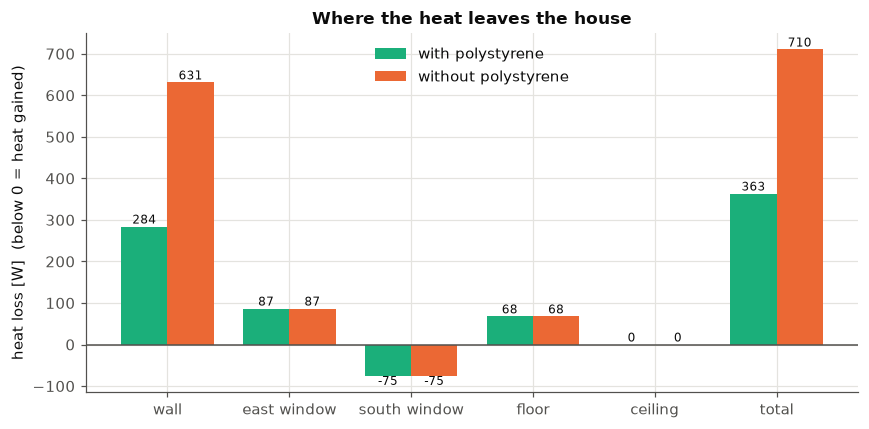

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
names = ["wall", "window_east", "window_south", "floor", "ceiling", "total"]
x = np.arange(len(names)); w = 0.38
b1 = ax.bar(x - w / 2, [with_eps[n] for n in names], w, color=AQUA, label="with polystyrene")
b2 = ax.bar(x + w / 2, [no_eps[n] for n in names], w, color=ORANGE, label="without polystyrene")
ax.bar_label(b1, fmt="%.0f", fontsize=8); ax.bar_label(b2, fmt="%.0f", fontsize=8)
ax.axhline(0, color=MUTED, lw=1)
ax.set_xticks(x); ax.set_xticklabels(["wall", "east window", "south window", "floor", "ceiling", "total"])
ax.set_ylabel("heat loss [W]  (below 0 = heat gained)"); ax.legend(frameon=False)
ax.set_title("Where the heat leaves the house")
plt.tight_layout(); plt.show()

**What this means.**
* **With the foam:** the house loses **363 W**, so the radiator uses **0.363 kWh each hour**.
* **Without the foam:** it loses **710 W**, so **0.710 kWh each hour**. The 10 cm of polystyrene **cuts the electricity bill almost in half (49 %)**.
* **The wall is the biggest hole:** 284 W with foam, 631 W without. The floor loses only **68 W**, because the soil under the house stays at 11 degC, much warmer than the outside air.
* **The ceiling is zero:** with the same temperature on both sides, nothing flows. Heat only moves when there is a difference.
* **The south window gains heat at noon:** **-75 W** (negative = heat comes in), because the sun pours in 380 W per square metre. The east window loses **+87 W** because the sun is weak there (55 W per square metre). Windows are not just holes; their direction matters.

# Q3: What does a thicker blanket do?

**Idea.** Same house, only the polystyrene thickness changes, from nothing to 20 cm.

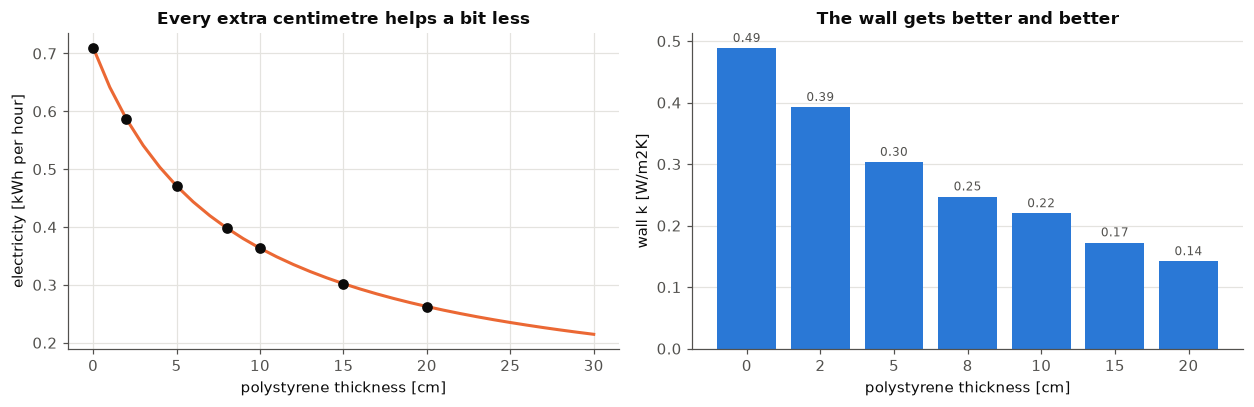

In [6]:
sweep = insulation_sweep([0, 0.02, 0.05, 0.08, 0.10, 0.15, 0.20])
fine = insulation_sweep(np.linspace(0, 0.30, 31))
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ax[0].plot(fine.eps_m * 100, fine.kWh_per_hour, color=ORANGE, lw=2)
ax[0].scatter(sweep.eps_m * 100, sweep.kWh_per_hour, color=INK, zorder=3)
ax[0].set_xlabel("polystyrene thickness [cm]"); ax[0].set_ylabel("electricity [kWh per hour]")
ax[0].set_title("Every extra centimetre helps a bit less")
ax[1].bar((sweep.eps_m * 100).astype(int).astype(str), sweep.k_wall, color=BLUE)
for i, v in enumerate(sweep.k_wall): ax[1].text(i, v + 0.01, f"{v:.2f}", ha="center", color=MUTED, fontsize=8)
ax[1].set_xlabel("polystyrene thickness [cm]"); ax[1].set_ylabel("wall k [W/m2K]"); ax[1].grid(axis="x", visible=False)
ax[1].set_title("The wall gets better and better")
plt.tight_layout(); plt.show()

**What this means.**
* **The first centimetres matter most:** the first 2 cm lower the total loss from 710 W to **586 W**, that is **62 W for every centimetre**. Between 8 cm and 10 cm each centimetre saves only about **18 W**, and between 15 cm and 20 cm only about **8 W**.
* **Diminishing returns:** it is like a blanket: the first one makes a huge difference, the tenth one hardly any. The savings shrink while the cost of foam grows with every centimetre, so a good designer stops where the extra savings stop paying for the extra foam.
* Doubling the sheet's 10 cm to **20 cm** lowers the load from 363 W to **263 W**, that is **0.263 kWh each hour**, but each of those extra watts costs more foam than the first ones did.
* The wall flux shows the same story: from **9.28 W/m2** (no foam) to **4.18 W/m2** (10 cm) to **2.70 W/m2** (20 cm).

# Q4: Which mix of materials makes the best wall?

**Idea.** Build every wall from three kinds of layer and let the computer rank them by k (smaller is better):
* a **structure** layer, 25 cm: reinforced concrete, solid brick, hollow brick or AAC,
* an **insulation** layer, 10 cm: mineral wool, EPS or XPS,
* cement plaster, 0.5 cm, on both sides.

All 12 mixes are 36 cm thick, so the comparison is fair.

![Conductivity of the materials: small lambda = good insulator, large lambda = lets heat through](images/conductivity-scale.svg)

*Figure: Conductivity of the materials: small lambda = good insulator, large lambda = lets heat through*

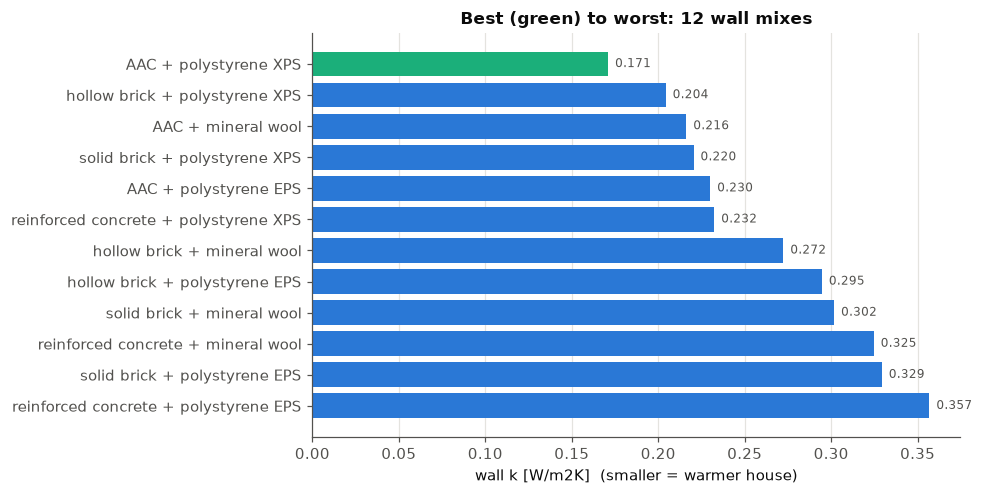

In [7]:
opts = wall_options()
labels = opts.structure + " + " + opts.insulation
fig, ax = plt.subplots(figsize=(9, 4.6))
ax.barh(labels[::-1], opts.k_wall[::-1], color=[AQUA if i == 0 else BLUE for i in range(len(opts))][::-1])
for i, v in enumerate(opts.k_wall[::-1]): ax.text(v + 0.004, i, f"{v:.3f}", va="center", fontsize=8, color=MUTED)
ax.set_xlabel("wall k [W/m2K]  (smaller = warmer house)"); ax.grid(axis="y", visible=False)
ax.set_title("Best (green) to worst: 12 wall mixes")
plt.tight_layout(); plt.show()

**What this means.**
* **Winner: AAC + XPS**, with **k = 0.171 W/(m2K)** (3.25 W per square metre). **Loser: reinforced concrete + EPS**, with **k = 0.357**, **twice as bad**, with the same wall thickness.
* **The insulation counts most:** XPS (lambda 0.025) beats mineral wool (0.036) and EPS (0.040) in **every** structure. Swapping EPS for XPS improves k by 0.06 for AAC and by 0.09 for hollow brick.
* **The structure counts too:** with the same XPS, AAC (k = 0.171) beats hollow brick (0.204), solid brick (0.220) and reinforced concrete (0.232). Concrete conducts heat about 14 times better than AAC (2.03 vs 0.15 W/(m K)), so a concrete wall needs much more foam to catch up.
* **A smart cheaper pair:** **AAC + mineral wool** (0.216) is nearly as good as **solid brick + XPS** (0.220), and mineral wool does not burn. So the "optimal" choice depends on what else matters: money, fire safety, strength. Thermally, the clear winner is **AAC + XPS**.
* The sheet's own wall (AAC + EPS, with thin plaster) is in the middle of the ranking at about 0.22 to 0.23. We can do better just by switching foam.

# Q5 to Q9: A thermostat that thinks about people

> **Thermostat**: a small box with a thermometer and a switch. You set the temperature you want (the **setpoint**); it keeps comparing the thermometer with the setpoint: too cold → heater ON, warm enough → heater OFF.

> **Heat load**: the heat per second the heater must supply to hold the setpoint; in steady state it equals the heat that leaks out.

**The old way:** the heater always holds **24 degC**, whatever people wear or do.

**The smart way:** the heater asks the comfort calculator, *"what is the lowest air temperature where people still feel fine (PMV >= -0.5)?"* and holds exactly that.

**Conditions from the sheet:** winter clothes (clo 1.0), RH 40 %, still air (0.1 m/s), and the walls are **2 degrees colder** than the air (tmr = ta - 2). The sheet's starter code says desk work **met = 1.2** but its notes say **met = 1.1**, so we do **both**.

**Recipe:**
1. Lower the setpoint step by step until the vote reaches **-0.5** (the root finder does this exactly).
2. Recompute the **heat load** of the house at that new temperature.
3. Compare the kWh per hour with the fixed 24 degC.

![From clothes and activity to the setpoint, then to the heat load and the electricity saved](images/ai-setpoint-chain.svg)

*Figure: From clothes and activity to the setpoint, then to the heat load and the electricity saved*

In [8]:
rows = []
for met in (1.2, 1.1):
    t_opt = optimal_setpoint(clo=1.0, met=met, rh=40, v=0.1, tmr_offset=-2)
    s = savings(t_opt)
    rows.append(dict(met=met, setpoint_degC=t_opt, pmv_at_setpoint=pmv(t_opt, t_opt - 2, 0.1, 40, 1.0, met),
                     ppd_at_setpoint=ppd(t_opt, t_opt - 2, 0.1, 40, 1.0, met), pmv_at_24=pmv(24, 22, 0.1, 40, 1.0, met),
                     load_24_W=s["load_fixed"], load_opt_W=s["load_opt"], kwh_24=s["kwh_fixed"], kwh_opt=s["kwh_opt"],
                     saving_W=s["saving_W"], saving_pct=s["saving_pct"]))
smart = pd.DataFrame(rows).set_index("met")
for met, r in smart.iterrows():
    print(f"met {met}: smart setpoint {r.setpoint_degC:.2f} degC (PMV {r.pmv_at_setpoint:.2f}, PPD {r.ppd_at_setpoint:.1f} %), "
          f"{r.kwh_24:.3f} -> {r.kwh_opt:.3f} kWh per hour, saving {r.saving_W:.0f} W = {r.saving_pct:.1f} %")

met 1.2: smart setpoint 20.23 degC (PMV -0.50, PPD 10.2 %), 0.363 -> 0.249 kWh per hour, saving 115 W = 31.6 %
met 1.1: smart setpoint 21.34 degC (PMV -0.50, PPD 10.2 %), 0.363 -> 0.282 kWh per hour, saving 81 W = 22.3 %


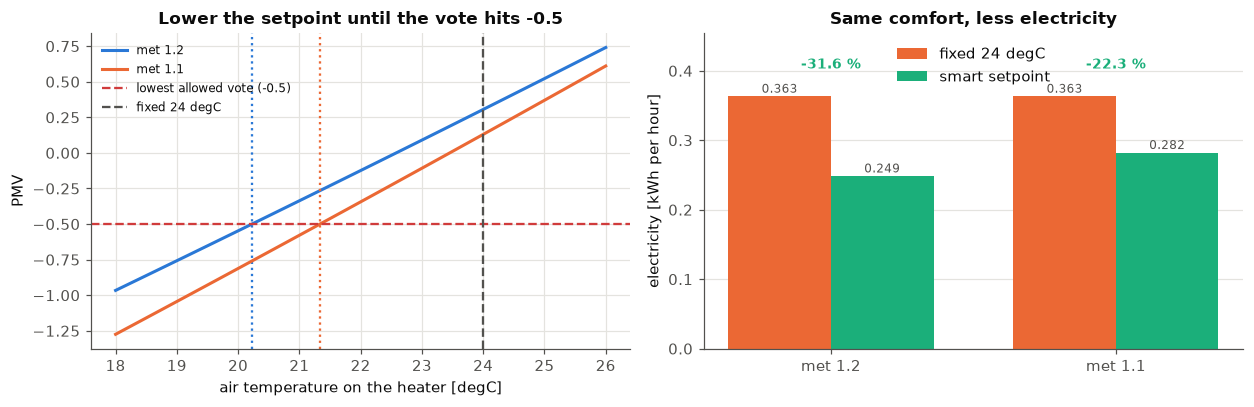

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.8))
ta = np.linspace(18, 26, 100)
for met, col in ((1.2, BLUE), (1.1, ORANGE)):
    ax[0].plot(ta, [pmv(t, t - 2, 0.1, 40, 1.0, met) for t in ta], color=col, lw=2, label=f"met {met}")
    ax[0].axvline(smart.loc[met, "setpoint_degC"], color=col, ls=":")
ax[0].axhline(-0.5, color=RED, ls="--", label="lowest allowed vote (-0.5)"); ax[0].axvline(24, color=MUTED, ls="--", label="fixed 24 degC")
ax[0].set_xlabel("air temperature on the heater [degC]"); ax[0].set_ylabel("PMV"); ax[0].legend(frameon=False, fontsize=8)
ax[0].set_title("Lower the setpoint until the vote hits -0.5")
x = np.arange(2); w = 0.36
ax[1].bar(x - w / 2, smart.kwh_24, w, color=ORANGE, label="fixed 24 degC")
ax[1].bar(x + w / 2, smart.kwh_opt, w, color=AQUA, label="smart setpoint")
for i, (a, b) in enumerate(zip(smart.kwh_24, smart.kwh_opt)):
    ax[1].text(i - w / 2, a + 0.005, f"{a:.3f}", ha="center", fontsize=8, color=MUTED)
    ax[1].text(i + w / 2, b + 0.005, f"{b:.3f}", ha="center", fontsize=8, color=MUTED)
for i, p in enumerate(smart.saving_pct): ax[1].text(i, max(smart.kwh_24.iloc[i], smart.kwh_opt.iloc[i]) + 0.04, f"-{p:.1f} %", ha="center", fontsize=9, fontweight="bold", color=AQUA)
ax[1].set_ylim(0, smart.kwh_24.max() * 1.25)
ax[1].set_xticks(x); ax[1].set_xticklabels([f"met {m}" for m in smart.index]); ax[1].set_ylabel("electricity [kWh per hour]")
ax[1].legend(frameon=False); ax[1].grid(axis="x", visible=False); ax[1].set_title("Same comfort, less electricity")
plt.tight_layout(); plt.show()

**What this means.**
* **Desk work, met 1.2:** the smart setpoint is **20.2 degC**, not 24. The radiator drops from **0.363 to 0.249 kWh per hour**, a saving of **115 W, or 31.6 %**.
* **A little less active, met 1.1:** the setpoint is **21.3 degC**, the radiator drops to **0.282 kWh per hour**, saving **81 W, or 22.3 %**. A person who produces a bit less body heat needs a slightly warmer room.
* **Always the same comfort at the edge:** the vote is exactly **-0.50** and about **10 out of 100** people would complain (PPD about 10 %). At the old 24 degC the vote is **+0.31** (met 1.2) or **+0.13** (met 1.1): people were **comfortably warm**, so the 24 degC was **overheating**.
* **Why the saving beats the sheet's "10 to 15 %":** the sheet says a few degrees usually save 10 to 15 %. Here we drop **3.8 degrees** (or 2.7) while the whole outside-inside gap is only 19 degrees, and the south window's free sunshine does not change with the setpoint. So each degree is a **bigger share** of what the heater really has to pay. In a house with a smaller gap or smaller gains the percentage would differ.
* **The core lesson of the sheet:** a few degrees of intelligence, **no loss of comfort**. The thermostat should follow **people** (clothes and activity), not a fixed number.
* **Careful:** we assumed the walls are exactly 2 degrees colder than the air. If the walls were warmer (as with the good insulation of Q1, whose inner surface is only 0.5 degrees below the air), the smart setpoint could go even lower; if the windows were colder, higher.

# One-page summary

* **Q1**: k = 0.22 W/m2K, q = 4.18 W/m2. The wall leaks about 4 watts per square metre, and the foam does most of the stopping
* **Q2**: 363 W (0.363 kWh/h) with foam, 710 W (0.710 kWh/h) without. The polystyrene halves the electricity bill; the south window even gains heat at noon
* **Q3**: 710 W at 0 cm, 363 W at 10 cm, 263 W at 20 cm. Thicker foam always helps, but each extra centimetre helps less
* **Q4**: best AAC + XPS (k 0.171), worst concrete + EPS (k 0.357). Insulation matters most, then the structure; thermally AAC + XPS wins
* **Q5 to Q9**: 20.2 degC (met 1.2) or 21.3 degC (met 1.1) instead of 24 degC, saving 31.6 % or 22.3 %. A thermostat that follows people saves a lot of electricity at no comfort cost